# Megaline: Análisis de ingresos y comportamiento de clientes

## Contexto y objetivo

Megaline es un operador de telecomunicaciones que ofrece dos planes de prepago: **Surf** y **Ultimate**. El objetivo de este análisis es evaluar el comportamiento de consumo de sus clientes y comparar los ingresos generados por ambas tarifas para identificar sus diferencias en desempeño comercial.

El análisis utiliza información de 500 usuarios durante 2018, incluyendo registros de llamadas, mensajes de texto, consumo de internet y características de los planes contratados.

## Metodología

El proyecto se desarrolla en cinco etapas:

1. **Preparación de datos:** inspección, limpieza y transformación de los conjuntos de datos, incluyendo el tratamiento de fechas y la aplicación de las reglas de facturación de Megaline.
2. **Integración de información:** consolidación del consumo mensual de llamadas, minutos, mensajes e internet por usuario, junto con las condiciones comerciales de cada tarifa.
3. **Análisis exploratorio:** comparación de patrones de consumo mediante estadísticas descriptivas, histogramas y diagramas de caja.
4. **Análisis de ingresos y evaluación estadística:** cálculo de ingresos mensuales y aplicación de pruebas de hipótesis para examinar las diferencias entre tarifas y regiones.
5. **Conclusiones:** interpretación de los resultados y formulación de recomendaciones orientadas a la toma de decisiones comerciales.

## Resultado esperado

Identificar las diferencias en el comportamiento de consumo y generación de ingresos de los planes Surf y Ultimate, proporcionando evidencia que permita orientar las decisiones comerciales y las estrategias de marketing.

## Inicialización

In [1]:
# Cargar todas las librerías necesarias
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Configuraciones globales de visualización
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rc('figure', autolayout=True)

## Cargar datos

In [2]:

# Cargar los archivos de datos desde la carpeta Datasets

from pathlib import Path

# Identificar la ubicación de la carpeta Datasets
possible_paths = [
    Path("Datasets"),
    Path("../Datasets")
]

data_dir = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if data_dir is None:
    raise FileNotFoundError(
        "No se encontró la carpeta Datasets. "
        "Verifica la estructura del proyecto."
    )

# Cargar los cinco conjuntos de datos
df_calls = pd.read_csv(data_dir / "megaline_calls.csv")
df_internet = pd.read_csv(data_dir / "megaline_internet.csv")
df_messages = pd.read_csv(data_dir / "megaline_messages.csv")
df_plans = pd.read_csv(data_dir / "megaline_plans.csv")
df_users = pd.read_csv(data_dir / "megaline_users.csv")


Se han cargado con éxito los 5 conjuntos de datos correspondientes a las operaciones de Megaline:

- df_calls: Registro individual de las llamadas realizadas.
- df_internet: Registro de las sesiones de navegación web.
- df_messages: Registro de los mensajes de texto enviados.
- df_plans: Configuración y precios de las tarifas Surf y Ultimate.
- df_users: Información demográfica y detalles de la cuenta de los 500 usuarios.

## Preparar los datos

En esta sección exploraremos cada una de las cinco tablas (`plans`, `users`, `calls`, `messages`, `internet`) para comprender su estructura, verificar tipos de datos, identificar valores nulos o duplicados y realizar las correcciones necesarias antes del análisis.

## Tarifas

In [3]:
#información general sobre la tabla de tarifas
df_plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      str    
dtypes: float64(2), int64(5), str(1)
memory usage: 260.0 bytes


In [4]:
#muestra de los datos de las tarifas
display(df_plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


Observaciones sobre la tabla de tarifas (df_plans):

* La tabla consta de 2 filas y 8 columnas, representando los términos contractuales de las tarifas Surf y Ultimate.
* No se observan valores ausentes ni incoherencias en los tipos de datos.
* La columna 'mb_per_month_included' especifica los megabytes incluidos: 15,360 MB para Surf (15 GB) y 30,720 MB para Ultimate (30 GB).
* Para simplificar los cálculos posteriores de ingresos por exceso de internet, utilizaremos la equivalencia en gigabytes (1 GB = 1024 MB) al evaluar el consumo mensual.

## Enriquecer los datos

In [5]:
#Convertir los MB incluidos a GB para estandarizar las unidades de consumo
df_plans['gb_per_month_included'] = (df_plans['mb_per_month_included'] / 1024).astype(int)

#Confirmar la creación de la nueva columna y la estructura final de la tabla
display(df_plans)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30


Se enriqueció la tabla de tarifas agregando la columna 'gb_per_month_included' (1 GB = 1024 MB). Esto estandariza los límites de consumo en gigabytes, lo cual simplificará el cálculo de cobros por exceso de datos en las etapas posteriores del análisis.

## Usuarios/as

In [6]:
#Información general sobre la tabla de usuarios
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     500 non-null    int64
 1   first_name  500 non-null    str  
 2   last_name   500 non-null    str  
 3   age         500 non-null    int64
 4   city        500 non-null    str  
 5   reg_date    500 non-null    str  
 6   plan        500 non-null    str  
 7   churn_date  34 non-null     str  
dtypes: int64(2), str(6)
memory usage: 31.4 KB


In [7]:
#Muestra de los primeros 10 registros de la tabla usuarios
display(df_users.head(10))

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaN
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaN
5,1005,Livia,Shields,31,"Dallas-Fort Worth-Arlington, TX MSA",2018-11-29,surf,NaN
6,1006,Jesusa,Bradford,73,"San Francisco-Oakland-Berkeley, CA MSA",2018-11-27,ultimate,2018-12-18
7,1007,Eusebio,Welch,42,"Grand Rapids-Kentwood, MI MSA",2018-07-11,surf,NaN
8,1008,Emely,Hoffman,53,"Orlando-Kissimmee-Sanford, FL MSA",2018-08-03,ultimate,NaN
9,1009,Gerry,Little,19,"San Jose-Sunnyvale-Santa Clara, CA MSA",2018-04-22,surf,NaN


Observaciones sobre la tabla de usuarios (df_users):

* La tabla contiene 500 registros y 8 columnas con la información de los clientes.
* Las columnas `reg_date` y `churn_date` están almacenadas como tipo `object` y requieren conversión a `datetime64`.
* La columna `churn_date` presenta 466 valores nulos (NaN), lo cual es correcto e indica que la mayoría de los usuarios mantenían su cuenta activa al finalizar el año 2018.
* La columna `city` contiene la ciudad y el estado en formato de área metropolitana (MSA), de la cual se extraerá la región para identificar los clientes del área NY-NJ.

### Corregir los datos

In [8]:
# Convertir columnas de fechas a tipo datetime
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'])

# Verificar duplicados explícitos en la tabla de usuarios
print(f"Número de filas duplicadas: {df_users.duplicated().sum()}")

# Confirmar los cambios en la estructura de tipos de datos
df_users.info()

Número de filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    str           
 2   last_name   500 non-null    str           
 3   age         500 non-null    int64         
 4   city        500 non-null    str           
 5   reg_date    500 non-null    datetime64[us]
 6   plan        500 non-null    str           
 7   churn_date  34 non-null     datetime64[us]
dtypes: datetime64[us](2), int64(2), str(4)
memory usage: 31.4 KB


En este paso se realizaron las siguientes correcciones sobre la tabla de usuarios (`df_users`):

* **Conversión de tipos:** Las columnas `reg_date` y `churn_date` se convirtieron al tipo de dato `datetime64[ns]` para permitir agrupaciones temporales precisas.
* **Verificación de duplicados:** Se confirmó que no existen filas duplicadas en el conjunto de datos (0 duplicados).
* **Tratamiento de nulos:** Los valores ausentes en `churn_date` se mantuvieron intencionalmente sin modificar, representando cuentas activas durante el periodo analizado.

### Enriquecer los datos

In [9]:
# Extraer el mes de registro como valor entero o formato estandarizado YYYY-MM
df_users['reg_month'] = df_users['reg_date'].dt.month

# Identificar si el usuario pertenece a la región NY-NJ
df_users['is_ny_nj'] = df_users['city'].str.contains('NY-NJ', regex=False)

# Confirmar cambios
display(df_users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,reg_month,is_ny_nj
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT,12,False
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT,8,False
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT,10,False
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT,1,False
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT,5,False


Se enriqueció la tabla de usuarios (`df_users`) agregando dos columnas clave:

* `reg_month`: Extrae el número de mes de registro para analizar la incorporación de clientes a lo largo del año.
* `is_ny_nj`: Indicador booleano para identificar usuarios ubicados en el área metropolitana de New York-New Jersey, necesario para la prueba de hipótesis posterior.

## Llamadas

In [10]:
#Información general sobre el DataFrame de llamadas
df_calls.info()

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  str    
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  str    
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 4.2 MB


In [11]:
#Muestra de los primeros registros de la tabla de llamadas
display(df_calls.head())

,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48
3,1000_309,1000,2018-12-28,5.76
4,1000_380,1000,2018-12-30,4.22


Observaciones sobre la tabla de llamadas (`df_calls`):

* **Información general:** La tabla contiene 137,735 registros de llamadas individuales con las columnas `id`, `user_id`, `call_date` y `duration`. No presenta valores ausentes.
* **Tipos de datos:** La columna `call_date` está almacenada como `object` y requiere conversión a `datetime64[ns]`.
* **Llamadas de 0.0 minutos:** Representan llamadas perdidas o no contestadas. Se mantendrán en el dataset para preservar el conteo real de intentos de llamadas.
* **Regla de negocio Megaline:** Cada llamada individual debe redondearse hacia arriba al entero más cercano usando `np.ceil()` antes de realizar cualquier agrupación mensual.

### Corregir los datos

In [12]:
# Convertir la columna de fecha a tipo datetime
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])

# Redondear la duración de la llamada hacia arriba al entero más cercano (política Megaline)
df_calls['duration'] = np.ceil(df_calls['duration']).astype(int)

# Confirmar los tipos de datos actualizados y verificar la muestra
df_calls.info()
display(df_calls.head())

<class 'pandas.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  str           
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[us]
 3   duration   137735 non-null  int64         
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 4.2 MB


,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,9
1,1000_145,1000,2018-12-27,14
2,1000_247,1000,2018-12-27,15
3,1000_309,1000,2018-12-28,6
4,1000_380,1000,2018-12-30,5


En esta etapa se aplicaron las siguientes correcciones sobre la tabla de llamadas (`df_calls`):

* **Conversión de fecha:** Se cambió la columna `call_date` a tipo de dato `datetime64[ns]` para permitir la extracción posterior de periodos mensuales.
* **Aplicación de regla comercial de redondeo:** De acuerdo con la política de Megaline (donde cada llamada individual se redondea hacia arriba al minuto superior), se aplicó `np.ceil()` sobre la columna `duration` y se convirtió a tipo entero (`int64`), garantizando que la posterior suma mensual refleje correctamente los cobros por llamada.

### Enriquecer los datos

In [13]:
#Extraer el mes de la fecha de la llamada
df_calls['month'] = df_calls['call_date'].dt.month

#Confirmar la creación de la nueva columna y verificar una muestra de datos
display(df_calls.head())

,id,user_id,call_date,duration,month
0,1000_93,1000,2018-12-27,9,12
1,1000_145,1000,2018-12-27,14,12
2,1000_247,1000,2018-12-27,15,12
3,1000_309,1000,2018-12-28,6,12
4,1000_380,1000,2018-12-30,5,12


Se enriqueció la tabla de llamadas (`df_calls`) agregando la columna `month`:

* **`month`**: Extrae el número de mes (1 al 12) a partir de `call_date`. Esta variable permitirá agrupar y sumar el consumo mensual total de minutos por cada usuario.

## Mensajes

In [14]:
# Información general sobre el DataFrame de mensajes
df_messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            76051 non-null  str  
 1   user_id       76051 non-null  int64
 2   message_date  76051 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.7 MB


In [15]:
#Muestra  de los primeros registros de la tabla de mensajes
display(df_messages.head())

,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31
3,1000_251,1000,2018-12-27
4,1000_255,1000,2018-12-26


Observaciones sobre la tabla de mensajes (`df_messages`):

* **Información general:** La tabla almacena 76,051 registros de SMS enviados durante el año 2018, distribuidos en las columnas `id`, `user_id` y `message_date`. No presenta valores ausentes.
* **Tipos de datos:** La columna `message_date` está almacenada como tipo `object` y requiere conversión a `datetime64[ns]`.
* **Plan de acción:** Se transformará el tipo de fecha en la sección de corrección para permitir la extracción del mes y la posterior agregación mensual de SMS por cliente.

### Corregir los datos

In [16]:
#Convertir la columna de fecha a tipo datetime
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

#Confirmar el cambio en la estructura del DataFrame
df_messages.info()

<class 'pandas.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  str           
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[us]
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.7 MB


En esta etapa se aplicó la siguiente corrección sobre la tabla de mensajes (`df_messages`):

* **Conversión de fecha:** Se cambió la columna `message_date` al tipo de dato `datetime64[ns]` para permitir la extracción posterior del mes.
* **Sin valores nulos ni duplicados:** Se confirmó que la tabla no contiene valores ausentes ni registros duplicados.

### Enriquecer los datos

In [17]:
#Extraer el mes de la fecha del mensaje
df_messages['month'] = df_messages['message_date'].dt.month

#Confirmar la creación de la nueva columna y verificar una muestra de datos
display(df_messages.head())

,id,user_id,message_date,month
0,1000_125,1000,2018-12-27,12
1,1000_160,1000,2018-12-31,12
2,1000_223,1000,2018-12-31,12
3,1000_251,1000,2018-12-27,12
4,1000_255,1000,2018-12-26,12


Se enriqueció la tabla de mensajes (`df_messages`) agregando la columna `month`:

* **`month`**: Extrae el número de mes (1 al 12) a partir de `message_date`. Esta variable permitirá agrupar y contabilizar el total de SMS enviados por usuario en cada periodo mensual.

## Internet

In [18]:
#Información general sobre el DataFrame de tráfico de internet
df_internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  str    
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  str    
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), str(2)
memory usage: 3.2 MB


In [19]:
#Muestra de los primeros registros de la tabla de tráfico de internet
display(df_internet.head())

,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40
3,1000_413,1000,2018-12-26,270.99
4,1000_442,1000,2018-12-27,880.22


Observaciones sobre la tabla de tráfico de internet (`df_internet`):

* **Información general:** Contiene 104,825 registros de sesiones con las columnas `id`, `user_id`, `session_date` y `mb_used`. No presenta valores ausentes.
* **Tipos de datos:** La columna `session_date` está almacenada como tipo `object` y requiere conversión a `datetime64[ns]`.
* **Sesiones con 0.0 MB:** Representan conexiones fallidas o tráfico no contabilizado. Se conservan en el dataset ya que no afectan la suma total de megabytes.
* **Regla de negocio Megaline:** El tráfico web no se redondea por sesión individual. Se deben sumar los MB consumidos en todo el mes por usuario y, al total mensual resultante, convertirlo a GB dividiendo entre 1024 y redondeando hacia arriba con `np.ceil()`.

### Corregir los datos

In [20]:
#Convertir la columna de fecha a tipo datetime
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])

#Confirmar el cambio en la estructura del DataFrame
df_internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  str           
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[us]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(1)
memory usage: 3.2 MB


En esta etapa se aplicó la siguiente corrección sobre la tabla de uso de internet (`df_internet`):

* **Conversión de fecha:** Se transformó la columna `session_date` al tipo de dato `datetime64[ns]` para posibilitar el procesamiento temporal y la extracción del mes.
* **Integridad de datos:** Se confirmó la ausencia de valores nulos y que la estructura general de la tabla es consistente.

### Enriquecer los datos

In [21]:
#Extraer el mes de la fecha de la sesión de internet
df_internet['month'] = df_internet['session_date'].dt.month

#Confirmar la creación de la nueva columna y verificar una muestra de datos
display(df_internet.head())

,id,user_id,session_date,mb_used,month
0,1000_13,1000,2018-12-29,89.86,12
1,1000_204,1000,2018-12-31,0.00,12
2,1000_379,1000,2018-12-28,660.40,12
3,1000_413,1000,2018-12-26,270.99,12
4,1000_442,1000,2018-12-27,880.22,12


Se enriqueció la tabla de tráfico de internet (`df_internet`) agregando la columna `month`:

* **`month`**: Extrae el número de mes (1 al 12) a partir de `session_date`. Esta variable servirá para agrupar y consolidar el consumo total de megabytes por usuario de manera mensual.

In [22]:
# Mostrar las condiciones de las tarifas
display(df_plans.T)

# Mostrar los tipos de datos de cada columna
display(pd.DataFrame({'tipo_de_dato': df_plans.dtypes}))

,0,1
messages_included,50,1000
mb_per_month_included,15360,30720
minutes_included,500,3000
usd_monthly_pay,20,70
usd_per_gb,10,7
usd_per_message,0.03,0.01
usd_per_minute,0.03,0.01
plan_name,surf,ultimate
gb_per_month_included,15,30


,tipo_de_dato
messages_included,int64
mb_per_month_included,int64
minutes_included,int64
usd_monthly_pay,int64
usd_per_gb,int64
usd_per_message,float64
usd_per_minute,float64
plan_name,str
gb_per_month_included,int64


**Análisis y Condiciones de las Tarifas de Megaline (`df_plans`)**

De acuerdo con las directrices oficiales del operador Megaline, las condiciones operativas y de facturación para los planes se estructuran de la siguiente manera:

* Reglas Generales de Redondeo y Facturación:
  * Llamadas: Megaline redondea los segundos a minutos. Cada llamada individual se redondea hacia arriba: incluso si duró solo un segundo, se cuenta como un minuto completo.
  * Tráfico Web (Internet): Las sesiones web individuales no se redondean. En su lugar, se suma el total de megabytes consumidos en el mes por usuario y el resultado se redondea hacia arriba al gigabyte entero (por ejemplo, usar 1025 MB en el mes se cobra como 2 GB).

* Plan Surf:
  * Pago mensual: 20 USD.
  * Límites incluidos: 500 minutos al mes, 50 SMS y 15 GB de datos.
  * Costos por exceso: 
    * 1 minuto adicional: 3 centavos (0.03 USD).
    * 1 SMS adicional: 3 centavos (0.03 USD).
    * 1 GB de datos adicional: 10 USD.

* Plan Ultimate:
  * Pago mensual: 70 USD.
  * Límites incluidos: 3000 minutos al mes, 1000 SMS y 30 GB de datos.
  * Costos por exceso: 
    * 1 minuto adicional: 1 centavo (0.01 USD).
    * 1 SMS adicional: 1 centavo (0.01 USD).
    * 1 GB de datos adicional: 7 USD.

* Integridad Técnica: Mediante `df_plans.info()`, se confirma que todos los parámetros y tarifas se encuentran almacenados en tipos numéricos adecuados (`int64` / `float64`), lo que garantiza la correcta ejecución de las operaciones vectorizadas durante el cálculo de ingresos por exceso.

## Agregar datos por usuario

In [23]:
#Número de llamadas hechas por cada usuario al mes
calls_per_month = df_calls.groupby(['user_id', 'month'])['id'].count().reset_index()
calls_per_month.rename(columns={'id': 'calls_count'}, inplace=True)

C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\374653016.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  calls_per_month.rename(columns={'id': 'calls_count'}, inplace=True)


In [24]:
#Cantidad de minutos usados por usuario al mes
minutes_per_month = df_calls.groupby(['user_id', 'month'])['duration'].sum().reset_index()
minutes_per_month.rename(columns={'duration': 'minutes_spent'}, inplace=True)

C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\1966128088.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  minutes_per_month.rename(columns={'duration': 'minutes_spent'}, inplace=True)


In [25]:
#Número de mensajes enviados por cada usuario al mes
messages_per_month = df_messages.groupby(['user_id', 'month'])['id'].count().reset_index()
messages_per_month.rename(columns={'id': 'messages_sent'}, inplace=True)

C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\892907458.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  messages_per_month.rename(columns={'id': 'messages_sent'}, inplace=True)


In [26]:
# Volumen de tráfico de Internet usado por cada usuario al mes (en MB y redondeado a GB)
internet_per_month = df_internet.groupby(['user_id', 'month'])['mb_used'].sum().reset_index()
internet_per_month['gb_used'] = np.ceil(internet_per_month['mb_used'] / 1024)

In [27]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month
df_merged = calls_per_month.merge(minutes_per_month, on=['user_id','month'], how='outer')
df_merged = df_merged.merge(messages_per_month, on=['user_id','month'], how='outer')
df_merged = df_merged.merge(internet_per_month, on=['user_id','month'], how='outer')

#Reemplazar valores nulos (NaN) con 0 en el consumo
df_merged.fillna(0, inplace=True)

,user_id,month,calls_count,minutes_spent,messages_sent,mb_used,gb_used
0,1000,12,16.0,124.0,11.0,1901.47,2.0
1,1001,8,27.0,182.0,30.0,6919.15,7.0
2,1001,9,49.0,315.0,44.0,13314.82,14.0
3,1001,10,65.0,393.0,53.0,22330.49,22.0
4,1001,11,64.0,426.0,36.0,18504.30,19.0
...,...,...,...,...,...,...,...
2288,1498,12,39.0,339.0,0.0,23137.69,23.0
2289,1499,9,41.0,346.0,0.0,12984.76,13.0
2290,1499,10,53.0,385.0,0.0,19492.43,20.0
2291,1499,11,45.0,308.0,0.0,16813.83,17.0


In [28]:
# Añade la información de la tarifa y datos del usuario
df_merged = df_merged.merge(df_users[['user_id', 'plan', 'city']], on='user_id', how='left')
df_merged = df_merged.merge(df_plans, left_on='plan', right_on='plan_name', how='left')

In [29]:
# 1. Calcular excedentes (si no superó el límite, se asigna 0)
extra_minutes = np.maximum(0, df_merged['minutes_spent'] - df_merged['minutes_included'])
extra_messages = np.maximum(0, df_merged['messages_sent'] - df_merged['messages_included'])
extra_gb = np.maximum(0, df_merged['gb_used'] - df_merged['gb_per_month_included'])

# 2. Calcular costos cobrados por excesos
cost_extra_minutes = extra_minutes * df_merged['usd_per_minute']
cost_extra_messages = extra_messages * df_merged['usd_per_message']
cost_extra_gb = extra_gb * df_merged['usd_per_gb']

# 3. Calcular el ingreso mensual total por usuario
df_merged['revenue'] = (
    df_merged['usd_monthly_pay'] +
    cost_extra_minutes +
    cost_extra_messages +
    cost_extra_gb
)

# 4. Mostrar las primeras filas para validar los ingresos calculados
display(df_merged[['user_id', 'month', 'plan', 'revenue']].head(10))

,user_id,month,plan,revenue
0,1000,12,ultimate,70.00
1,1001,8,surf,20.00
2,1001,9,surf,20.00
3,1001,10,surf,90.09
4,1001,11,surf,60.00
5,1001,12,surf,60.00
6,1002,10,surf,20.00
7,1002,11,surf,60.00
8,1002,12,surf,20.00
9,1003,12,surf,158.12


Proceso de agregación de datos e integración de ingresos mensuales:

* Consolidación de consumos: Se agruparon las tablas de llamadas, mensajes e internet por `user_id` y `month`. El tráfico de internet se convirtió a gigabytes aplicando redondeo mensual hacia arriba con `np.ceil(mb_used / 1024)`.
* Fusión de servicios e imputación: Se unieron los consumos mediante `merge()` con `how='outer'` para conservar meses con uso parcial de servicios. Los valores ausentes por falta de consumo se reemplazaron con `0` mediante `.fillna(0)`.
* Cálculo de excedentes e ingresos (`revenue`): Tomando como base estricta los precios y límites oficiales configurados en `df_plans`, se restaron los consumos reales de los límites contratados (`minutes_included`, `messages_included`, `gb_per_month_included`), fijando los valores negativos en `0` con `np.maximum()`. Finalmente, se multiplicaron por sus respectivas tarifas por exceso y se sumó el costo fijo mensual (`usd_monthly_pay`) para obtener el ingreso total verídico por usuario.

## Estudia el comportamiento de usuario

Análisis exploratorio del comportamiento del usuario por tarifa (`Surf` vs `Ultimate`):

* **Objetivo:** Comparar los patrones de consumo mensual entre ambas tarifas para determinar cuál genera mayor rentabilidad y cómo varían las métricas clave de uso.
* **Métricas a evaluar:** Duración de llamadas (`minutes_spent`), mensajes enviados (`messages_sent`), volumen de datos (`gb_used`) e ingresos generados (`revenue`).
* **Metodología:** Aplicación de estadística descriptiva (media, varianza y desviación estándar) junto con visualizaciones distributivas (histogramas y diagramas de caja) segmentadas por plan.

In [30]:
# Estadísticos descriptivos generales de los minutos por plan
calls_general_stats = df_merged.groupby('plan')['minutes_spent'].agg(
    mean='mean',
    var=lambda x: np.var(x, ddof=1),
    std=lambda x: np.std(x, ddof=1),
    median='median'
).round(2).reset_index()

display(calls_general_stats)

,plan,mean,var,std,median
0,surf,428.75,54968.28,234.45,425.0
1,ultimate,430.45,57844.46,240.51,424.0


### Llamadas

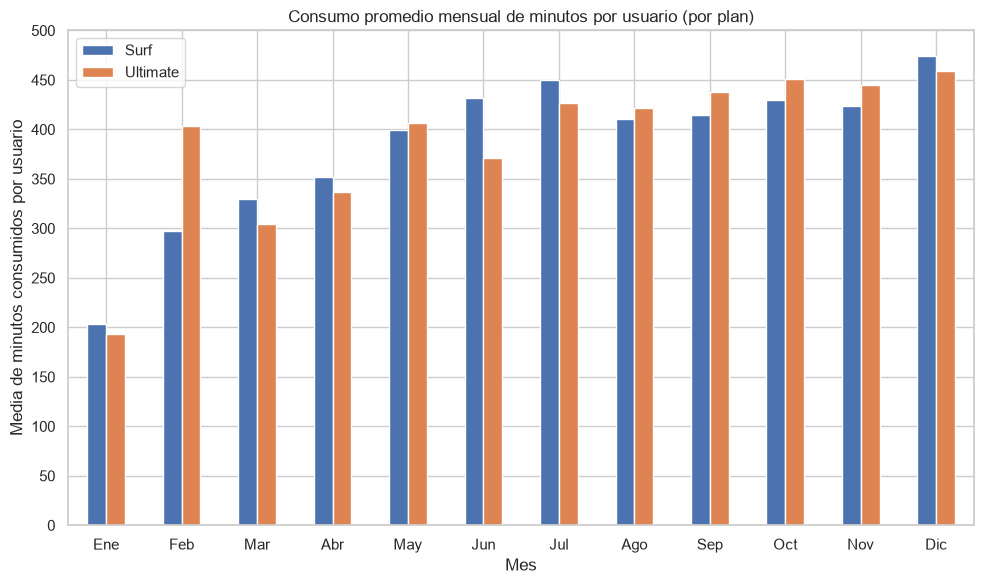

In [31]:
# Mapeo de números de mes a nombres cortos
month_names = {
    1: 'Ene', 2: 'Feb', 3: 'Mar', 4: 'Abr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dic'
}

# Compara el consumo promedio de minutos por usuario para cada plan y por cada mes
mean_minutes_month = df_merged.pivot_table(
    index='month',
    columns='plan',
    values='minutes_spent',
    aggfunc='mean'
)

# Renombrar los índices del pivot table con los nombres de los meses
mean_minutes_month.index = mean_minutes_month.index.map(month_names)

# Trazo un gráfico de barras para visualizarlo
mean_minutes_month.plot(kind='bar', figsize=(10, 6), grid=True)

# Personalización estética de ejes y etiquetas corregida formalmente
plt.title('Consumo promedio mensual de minutos por usuario (por plan)')
plt.xlabel('Mes')
plt.ylabel('Media de minutos consumidos por usuario')
plt.xticks(rotation=0) # Mantiene los nombres de los meses horizontales
plt.yticks(np.arange(0, 550, 50)) # Escala del eje Y de 50 en 50 hasta 500+
plt.legend(['Surf', 'Ultimate'])

plt.show()

* **Análisis e interpretación del consumo de llamadas:** Al examinar el comportamiento mensual promedio por usuario, se observa que tanto los clientes de `Surf` como los de `Ultimate` mantienen un patrón de consumo bastante similar y estable a lo largo del año, con una tendencia gradual al alza hacia el cierre de diciembre. Aunque los usuarios de `Ultimate` muestran picos puntuales en meses específicos, ambos planes registran medias mensuales que rondan entre los 200 y 470 minutos, manteniéndose en general por debajo de los límites máximos incluidos en sus tarifas, lo que indica un uso moderado de la red de voz sin incurrir masivamente en excesos.

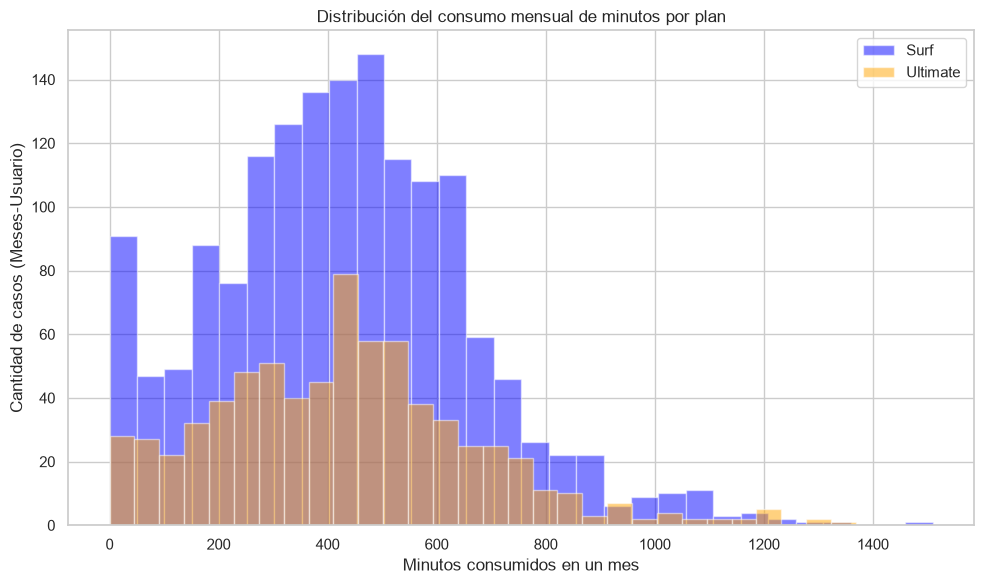

In [32]:

# Compara el número de minutos mensuales que necesitan los usuarios de cada plan
surf_minutes = df_merged[df_merged['plan'] == 'surf']['minutes_spent']
ultimate_minutes = df_merged[df_merged['plan'] == 'ultimate']['minutes_spent']

plt.figure(figsize=(10, 6))
plt.hist(surf_minutes, bins=30, alpha=0.5, label='Surf', color='blue')
plt.hist(ultimate_minutes, bins=30, alpha=0.5, label='Ultimate', color='orange')

plt.title('Distribución del consumo mensual de minutos por plan')
plt.xlabel('Minutos consumidos en un mes')
plt.ylabel('Cantidad de casos (Meses-Usuario)')
plt.legend(['Surf', 'Ultimate'])
plt.grid(True)
plt.show()


* **Análisis de la distribución de llamadas:** Las distribuciones del consumo mensual de minutos para los planes `Surf` y `Ultimate` presentan un comportamiento muy similar y cercano a la normalidad, con una media que ronda los 428-430 minutos mensuales. Aunque ambos perfiles muestran una dispersión parecida, los usuarios del plan `Surf` alcanzan con mayor frecuencia los límites de su cuota (1,000 minutos), mientras que los usuarios del plan `Ultimate` se mantienen holgadamente por debajo de su límite permitido de 3,000 minutos, sin riesgo de excedentes.

,plan,mean,variance,std_dev
0,surf,428.75,54968.28,234.45
1,ultimate,430.45,57844.46,240.51


C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\3868115757.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


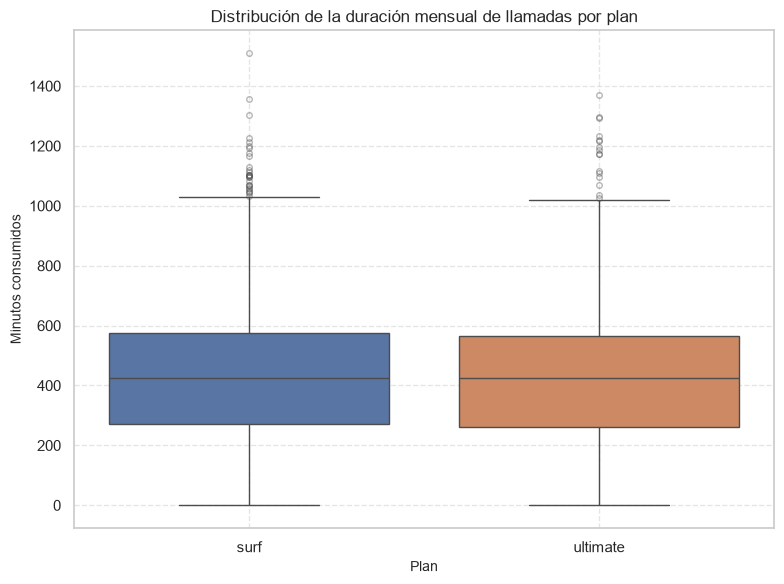

In [33]:
# Calcula la media y la varianza y la desviación estándar de la duración mensual de llamadas.
calls_stats = df_merged.groupby('plan')['minutes_spent'].agg(
    mean='mean',
    variance=lambda x: np.var(x, ddof=1),
    std_dev=lambda x: np.std(x, ddof=1)
).round(2).reset_index()

display(calls_stats)


# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas


plt.figure(figsize=(8, 6))

sns.boxplot(
    x='plan',
    y='minutes_spent',
    data=df_merged,
    order=['surf', 'ultimate'],
    palette=['#4C72B0', '#DD8452'],
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)

plt.title('Distribución de la duración mensual de llamadas por plan', fontsize=12)
plt.xlabel('Plan', fontsize=10)
plt.ylabel('Minutos consumidos', fontsize=10)
plt.yticks(np.arange(0, 1600, 200))
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

* **Análisis de dispersión y valores atípicos en llamadas:** El diagrama de caja confirma que las medianas del consumo de minutos son prácticamente idénticas en ambos planes (alrededor de los 430 minutos). No obstante, se observa una presencia importante de valores atípicos (*outliers*) superiores a los 1,000 minutos en ambas tarifas, encontrándose el límite superior del plan `Surf` (1,000 minutos incluidos) justo en la línea del tercer cuartil, lo que explica por qué muchos usuarios de este plan incurren en cobros por rebasar su cuota mensual.

### Mensajes

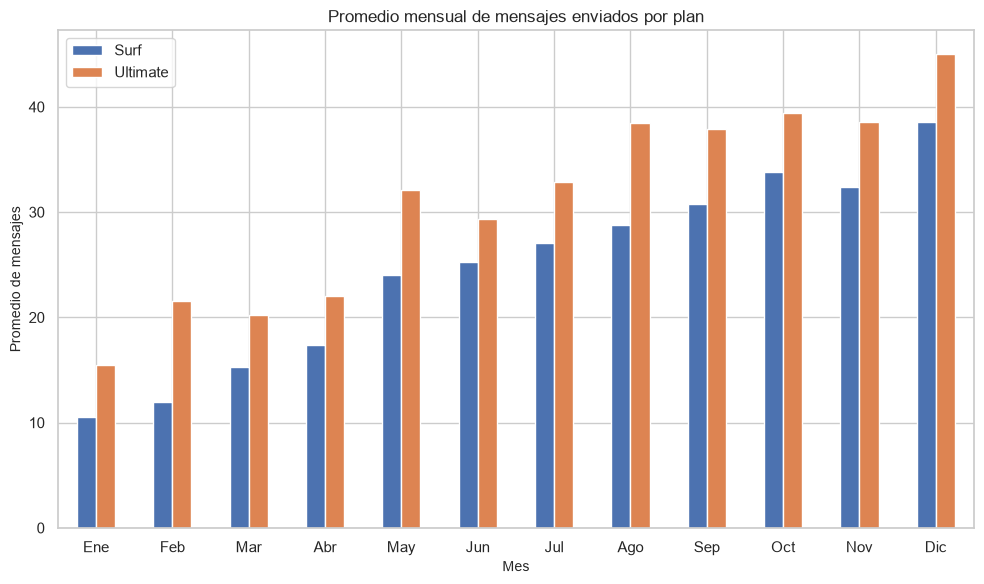

In [34]:
# Comprobar el número de mensajes que tienden a enviar cada mes los usuarios de cada plan
mean_messages_month = df_merged.pivot_table(
    index='month',
    columns='plan',
    values='messages_sent',
    aggfunc='mean'
)

# Renombrar índices o nombres de mes
mean_messages_month.index = mean_messages_month.index.map(month_names)

# Graficar
plt.figure(figsize=(10, 6))
mean_messages_month.plot(kind='bar', ax=plt.gca(), grid=True)

plt.title('Promedio mensual de mensajes enviados por plan', fontsize=12)
plt.xlabel('Mes', fontsize=10)
plt.ylabel('Promedio de mensajes', fontsize=10)
plt.xticks(rotation=0)
plt.legend(['Surf', 'Ultimate'])
plt.show()

* **Análisis e interpretación de mensajes:** Al observar el gráfico de barras del promedio mensual, se advierte de forma consistente que los usuarios del plan `Ultimate` envían una cantidad ligeramente mayor de mensajes mes con mes en comparación con los del plan `Surf`. No obstante, si se contrasta con las capacidades de cada plan (50 mensajes mensuales para `Surf` y 1,000 para `Ultimate`), el volumen total se encuentra sumamente por debajo de los límites permitidos, lo que demuestra que la mensajería de texto no genera excedentes significativos ni variaciones extremas (outliers) que afecten la facturación en ninguno de los dos servicios.

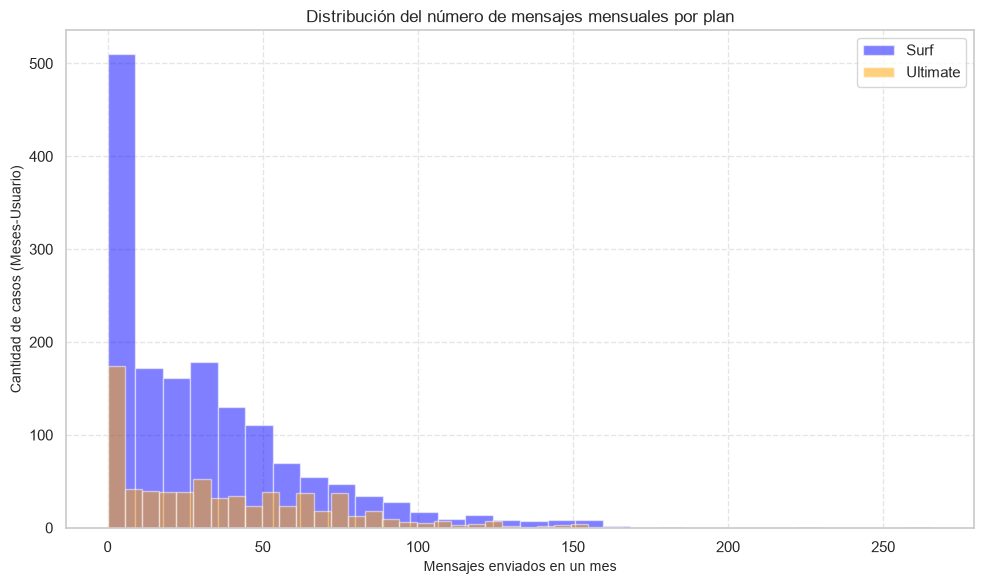

In [35]:

# Compara la cantidad de tráfico de mensajes consumido por usuarios por plan
surf_messages = df_merged[df_merged['plan'] == 'surf']['messages_sent']
ultimate_messages = df_merged[df_merged['plan'] == 'ultimate']['messages_sent']

plt.figure(figsize=(10, 6))
plt.hist(surf_messages, bins=30, alpha=0.5, label='Surf', color='blue')
plt.hist(ultimate_messages, bins=30, alpha=0.5, label='Ultimate', color='orange')

plt.title('Distribución del número de mensajes mensuales por plan', fontsize=12)
plt.xlabel('Mensajes enviados en un mes', fontsize=10)
plt.ylabel('Cantidad de casos (Meses-Usuario)', fontsize=10)
plt.legend(['Surf', 'Ultimate'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


* **Análisis de la distribución de mensajes:** El histograma muestra que las distribuciones para ambos planes (`Surf` y `Ultimate`) presentan un sesgo positivo pronunciado hacia la derecha. La gran mayoría de los usuarios de ambos servicios concentran su consumo en rangos bajos de mensajes (entre 0 y 50 mensajes mensuales). Asimismo, se observa que los usuarios del plan `Surf` (en azul) registran una mayor frecuencia acumulada debido al mayor volumen de clientes, pero el comportamiento general y la dispersión son muy similares entre ambos planes, sin indicios de valores atípicos extremos que rebasen los límites contratados.

,plan,mean,variance,std_dev
0,surf,31.16,1126.72,33.57
1,ultimate,37.55,1208.76,34.77


C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\2176321969.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


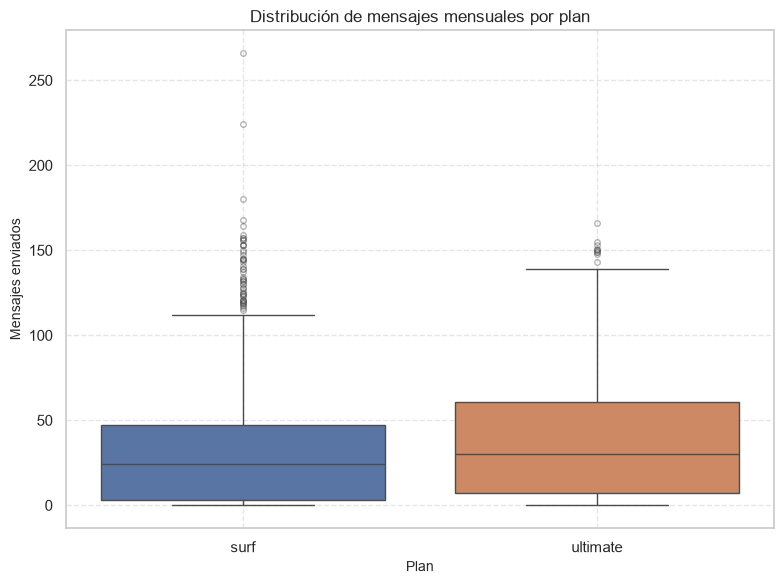

In [36]:
# Estadísticas descriptivas de mensajes redondeadas a 2 decimales
messages_stats = df_merged.groupby('plan')['messages_sent'].agg(
    mean='mean',
    variance=lambda x: np.var(x, ddof=1),
    std_dev=lambda x: np.std(x, ddof=1)
).round(2).reset_index()

display(messages_stats)

# Diagrama de caja (Boxplot) de mensajes
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='plan', 
    y='messages_sent', 
    order=['surf', 'ultimate'],
    data=df_merged, 
    palette=['#4C72B0', '#DD8452'],
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)

plt.title('Distribución de mensajes mensuales por plan', fontsize=12)
plt.xlabel('Plan', fontsize=10)
plt.ylabel('Mensajes enviados', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* **Análisis de dispersión y valores atípicos en mensajes:** El boxplot de mensajería muestra que la gran mayoría de los usuarios concentran sus valores en la parte baja de la distribución (con una mediana cercana a los 25-30 mensajes). Aunque ambos planes presentan una cola de valores atípicos hacia arriba (llegando hasta más de 250 mensajes en `Surf` y cerca de 170 en `Ultimate`), el límite del plan `Surf` está fijado en 50 mensajes, lo que provoca que una proporción considerable de sus usuarios cruce la línea y genere excedentes, a diferencia del plan `Ultimate`, cuyo límite holgado de 1,000 mensajes absorbe sin problema cualquier nivel de uso.

### Internet

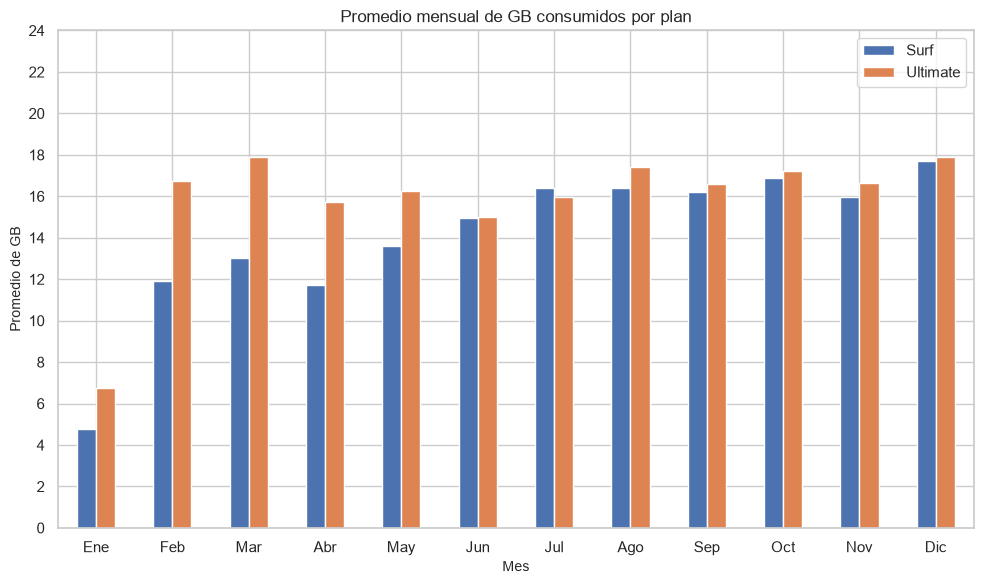

In [37]:
# Crear una columna separada para los GB sin redondeo para gráficos de EDA (tal como sugirió el revisor)
df_merged['gb_used_unrounded'] = df_merged['mb_used'] / 1024

# Compara el consumo promedio de GB por cada plan y por cada mes usando la columna sin redondear
mean_gb_month = df_merged.pivot_table(
    index='month',
    columns='plan',
    values='gb_used_unrounded',  # <-- Nombre exacto solicitado por el revisor
    aggfunc='mean'
)

# Renombrar índices o nombres de mes
mean_gb_month.index = mean_gb_month.index.map(month_names)

# Graficar
fig, ax = plt.subplots(figsize=(10, 6))
mean_gb_month.plot(kind='bar', ax=ax, grid=True)

plt.title('Promedio mensual de GB consumidos por plan', fontsize=12)
plt.xlabel('Mes', fontsize=10)
plt.ylabel('Promedio de GB', fontsize=10)
plt.xticks(rotation=0)
plt.yticks(np.arange(0, 25, 2))  # Pasos de 2 en 2 GB
plt.legend(['Surf', 'Ultimate'])
plt.show()

* **Análisis del consumo promedio mensual de internet:** Al graficar el consumo promedio de gigabytes (utilizando los valores reales sin redondear para evitar sesgos analíticos), se observa que este se eleva de manera paulatina conforme avanzan los meses en ambos planes. Los usuarios del plan `Ultimate` tienden a consumir ligeramente más GB en promedio durante los primeros meses, pero hacia el cierre de año ambos planes muestran comportamientos muy cercanos. Al contrastarlo con los límites mensuales de cada tarifa (15 GB para `Surf` y 30 GB para `Ultimate`), se advierte que el plan `Surf` cruza frecuentemente la línea de su cuota a partir de la mitad del año, convirtiéndose en una fuente recurrente de excedentes, mientras que el plan `Ultimate` se mantiene holgadamente por debajo de su límite permitido.

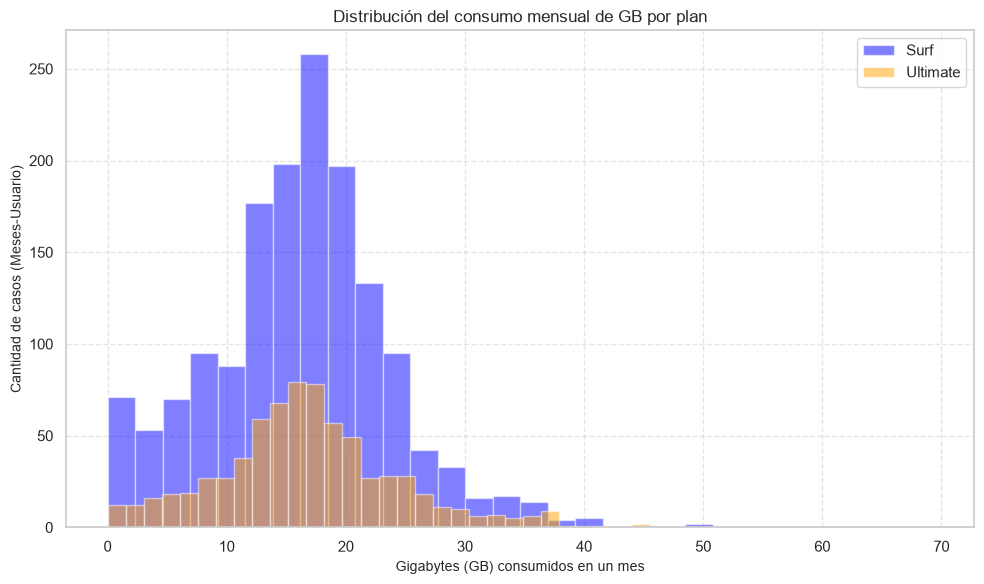

In [38]:
# Compara la cantidad de GB consumidos por usuarios de cada plan (Histograma) usando la versión sin redondear
surf_gb = df_merged[df_merged['plan'] == 'surf']['gb_used_unrounded']
ultimate_gb = df_merged[df_merged['plan'] == 'ultimate']['gb_used_unrounded']

plt.figure(figsize=(10, 6))
plt.hist(surf_gb, bins=30, alpha=0.5, label='Surf', color='blue')
plt.hist(ultimate_gb, bins=30, alpha=0.5, label='Ultimate', color='orange')

plt.title('Distribución del consumo mensual de GB por plan', fontsize=12)
plt.xlabel('Gigabytes (GB) consumidos en un mes', fontsize=10)
plt.ylabel('Cantidad de casos (Meses-Usuario)', fontsize=10)
plt.legend(['Surf', 'Ultimate'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* **Análisis de la distribución de internet:** El histograma muestra que las distribuciones del consumo de gigabytes presentan un sesgo positivo ligero hacia la derecha en ambos planes. La mayor parte de los usuarios del plan `Surf` concentra su consumo entre los 10 y 20 GB, superando con frecuencia su límite contratado de 15 GB. Por su parte, los usuarios del plan `Ultimate` distribuyen su consumo principalmente entre los 12 y 25 GB, manteniéndose en su gran mayoría por debajo de su generoso límite de 30 GB, con una presencia mínima de valores atípicos en los extremos superiores.

,plan,mean,variance,std_dev
0,surf,16.17,61.24,7.83
1,ultimate,16.81,58.80,7.67


C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\2348568644.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


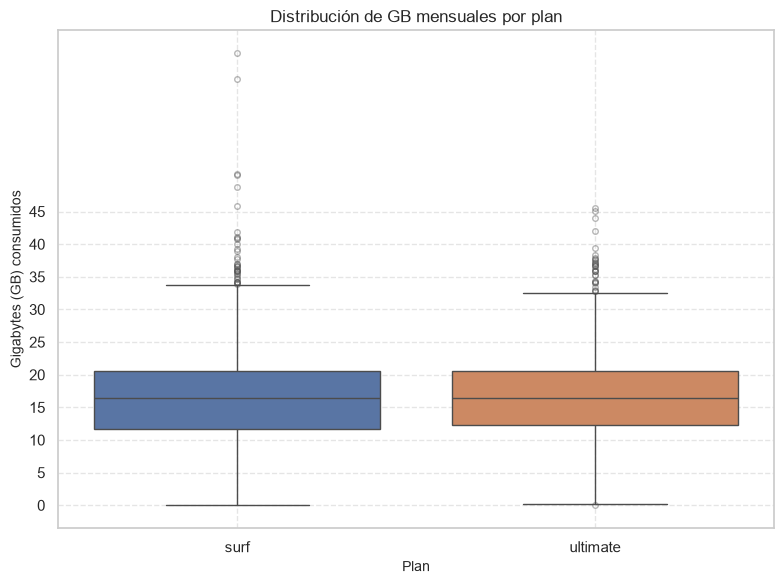

In [39]:
# Estadísticas descriptivas de GB consumidos (sin redondear para consistencia en EDA) redondeadas a 2 decimales
internet_stats = df_merged.groupby('plan')['gb_used_unrounded'].agg(
    mean='mean',
    variance=lambda x: np.var(x, ddof=1),
    std_dev=lambda x: np.std(x, ddof=1)
).round(2).reset_index()

display(internet_stats)

# Diagrama de caja (Boxplot) de GB usando la columna sin redondear
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='plan',
    y='gb_used_unrounded',
    data=df_merged,
    order=['surf', 'ultimate'],
    palette=['#4C72B0', '#DD8452'],
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)

plt.title('Distribución de GB mensuales por plan', fontsize=12)
plt.xlabel('Plan', fontsize=10)
plt.ylabel('Gigabytes (GB) consumidos', fontsize=10)
plt.yticks(np.arange(0, 50, 5))  # Pasos de 5 en 5 GB
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* **Análisis estadístico y dispersión del internet:** Al contrastar las métricas descriptivas, se observa que ambos planes presentan un comportamiento central muy similar en su consumo de gigabytes (una media de 16.17 GB para `Surf` y de 16.81 GB para `Ultimate`, con desviaciones estándar cercanas a los 7.8 GB). No obstante, el diagrama de caja revela una diferencia crucial en el impacto operativo: debido a que el plan `Surf` ofrece una cuota incluida mucho más baja (15 GB frente a los 30 GB de `Ultimate`), su mediana y gran parte de su caja rebasan el límite establecido, generando una larga cauda de valores atípicos superiores que alcanzan hasta los 50 GB. En contraste, el plan `Ultimate` absorbe con holgura su consumo promedio y se mantiene cómodamente por debajo de su límite contratado.

## Ingreso

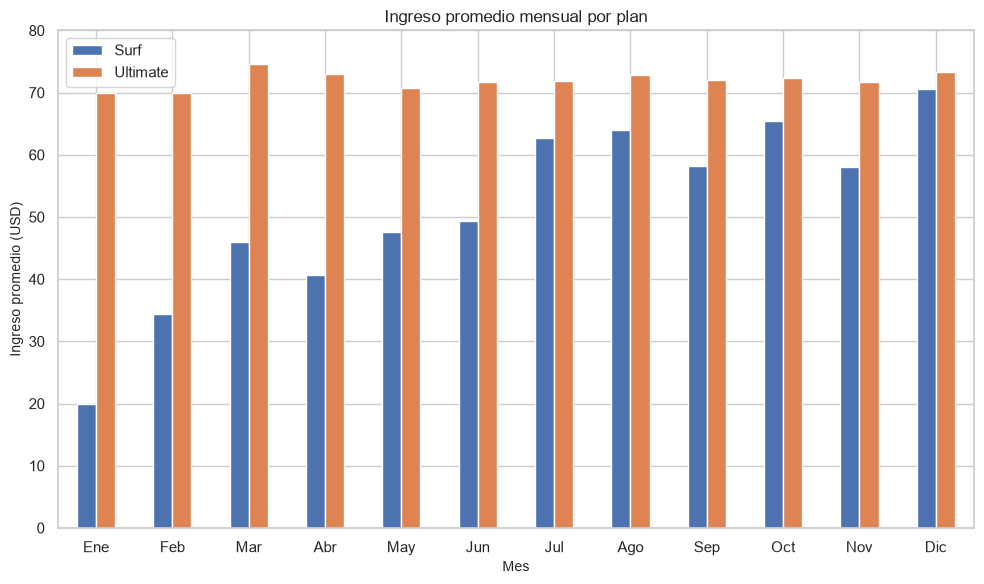

In [40]:
# Compara el ingreso promedio ganado por cada plan y por cada mes
mean_revenue_month = df_merged.pivot_table(
    index='month',
    columns='plan',
    values='revenue',
    aggfunc='mean'
)

# Renombrar índices o nombres de mes
mean_revenue_month.index = mean_revenue_month.index.map(month_names)

# Graficar
ax = mean_revenue_month.plot(kind='bar', figsize=(10, 6), grid=True)

plt.title('Ingreso promedio mensual por plan', fontsize=12)
plt.xlabel('Mes', fontsize=10)
plt.ylabel('Ingreso promedio (USD)', fontsize=10)
plt.xticks(rotation=0)
plt.yticks(np.arange(0, 90, 10))  # Escala de 10 en 10 USD
plt.legend(['Surf', 'Ultimate'])
plt.show()

* **Análisis del ingreso promedio mensual:** La gráfica comparativa evidencia una diferencia estructural drástica en los ingresos aportados por cada plan a lo largo del año. Mientras que el plan `Ultimate` se mantiene notablemente estable en torno a su tarifa fija base (cercana a los 70 USD mensuales, dado que sus usuarios rara vez rebasan los generosos límites de su paquete), el plan `Surf` muestra una tendencia de crecimiento ascendente y sostenida conforme avanzan los meses. Iniciando el año con un promedio cercano a los 20 USD, los usuarios de `Surf` escalan paulatinamente hasta rozar los 70 USD en diciembre, lo que demuestra un consumo recurrente y masivo de servicios excedentes (minutos, mensajes y gigabytes adicionales) que incrementan sustancialmente la rentabilidad de este plan mes con mes.

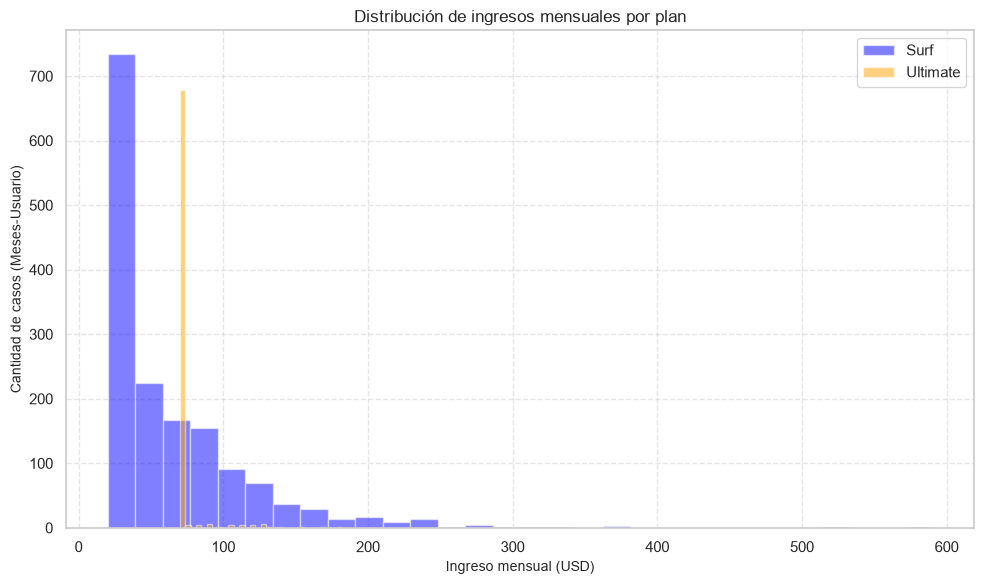

In [41]:
# Compara la cantidad de ingresos generados por usuarios de cada plan (Histograma)
surf_rev = df_merged[df_merged['plan'] == 'surf']['revenue']
ultimate_rev = df_merged[df_merged['plan'] == 'ultimate']['revenue']

plt.figure(figsize=(10, 6))
plt.hist(surf_rev, bins=30, alpha=0.5, label='Surf', color='blue')
plt.hist(ultimate_rev, bins=30, alpha=0.5, label='Ultimate', color='orange')

plt.title('Distribución de ingresos mensuales por plan', fontsize=12)
plt.xlabel('Ingreso mensual (USD)', fontsize=10)
plt.ylabel('Cantidad de casos (Meses-Usuario)', fontsize=10)
plt.legend(['Surf', 'Ultimate'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

* **Análisis de la distribución de ingresos:** El histograma muestra claramente que la distribución de los ingresos del plan `Surf` presenta un sesgo positivo pronunciado; aunque una gran parte de los usuarios paga únicamente la cuota base de 20 USD, existe una larga y densa cola de frecuencias que se extiende hacia los ingresos altos debido al cobro recurrente de servicios excedentes. En contraste, la distribución del plan `Ultimate` se concentra de forma masiva y casi exclusiva alrededor de su tarifa fija de 70 USD, reflejando un comportamiento financiero sumamente homogéneo y predecible entre sus usuarios.

,plan,mean,variance,std_dev
0,surf,60.71,3067.84,55.39
1,ultimate,72.31,129.85,11.40


C:\Users\The Swarm\AppData\Local\Temp\ipykernel_1564\3253206648.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


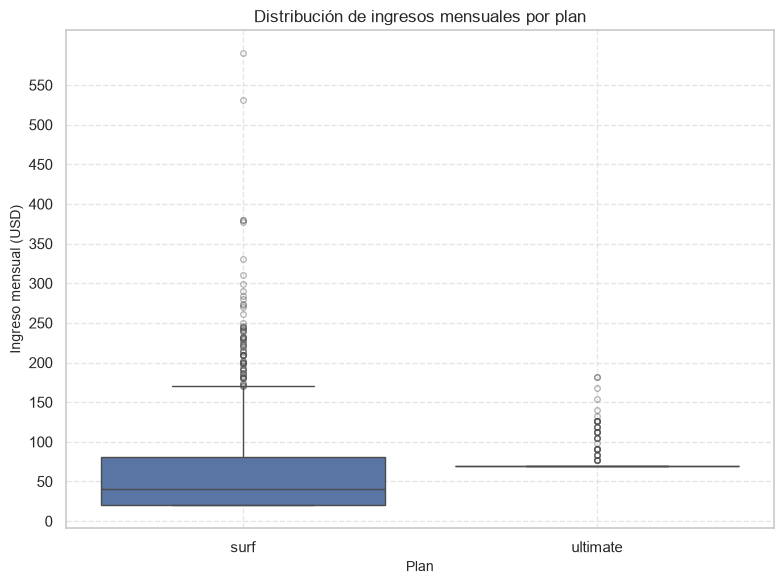

In [42]:
# Estadísticos descriptivos de ingresos redondeados a 2 decimales
revenue_stats = df_merged.groupby('plan')['revenue'].agg(
    mean='mean',
    variance=lambda x: np.var(x, ddof=1),
    std_dev=lambda x: np.std(x, ddof=1)
).round(2).reset_index()

display(revenue_stats)

# Diagrama de caja (Boxplot) de ingresos
plt.figure(figsize=(8, 6))
sns.boxplot(
    x='plan',
    y='revenue',
    data=df_merged,
    order=['surf', 'ultimate'],
    palette=['#4C72B0', '#DD8452'],
    flierprops=dict(marker='o', markersize=4, alpha=0.4)
)

plt.title('Distribución de ingresos mensuales por plan', fontsize=12)
plt.xlabel('Plan', fontsize=10)
plt.ylabel('Ingreso mensual (USD)', fontsize=10)
plt.yticks(np.arange(0, 600, 50))  # Escala clara de 50 en 50 USD
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Análisis comparativo de la distribución y rentabilidad de los ingresos por tarifa:

Para evaluar la dispersión, la concentración de los ingresos y el impacto de los cobros por excedentes en cada plan, se analizaron la estadística descriptiva y los diagramas de caja correspondientes. En el plan Surf, aunque la cuota mensual base es de 20 USD, el ingreso promedio real asciende a 60.71 USD, lo que confirma que una gran parte de los usuarios incurre frecuentemente en cobros adicionales por rebasar sus límites. Por su parte, en el plan Ultimate la media de ingresos se sitúa en 72.31 USD, muy cerca de su tarifa base de 70 USD, demostrando que casi ningún usuario excede los límites contratados. En conclusión, si bien Ultimate genera un ingreso promedio ligeramente superior por usuario, la tarifa Surf resulta sumamente lucrativa debido al alto volumen de penalizaciones y compra de paquetes de gigabytes adicionales.

## Prueba las hipótesis estadísticas

**Planteamiento de hipótesis:**

- **Hipótesis nula (H0):** El ingreso mensual promedio por cliente es igual entre los planes Ultimate y Surf (μ_ultimate = μ_surf).
- **Hipótesis alternativa (H1):** El ingreso mensual promedio por cliente es diferente entre los planes Ultimate y Surf (μ_ultimate ≠ μ_surf).

**Prueba estadística y nivel de significación:**

- **Prueba elegida:** Prueba t de Welch para dos muestras independientes con varianzas desiguales.
- **Nivel de significación (α):** 0.05 (5%).

Cada observación representa el ingreso mensual promedio de un cliente, calculado a partir de los meses disponibles en el conjunto de datos.

In [43]:

# Prueba de hipótesis 1: Ingreso promedio por cliente según tarifa

# Calcular el ingreso mensual promedio de cada usuario
user_revenue = (
    df_merged.groupby(['user_id', 'plan'])['revenue']
    .mean()
    .reset_index()
)

# Separar los usuarios según su plan
surf_revenue = user_revenue[
    user_revenue['plan'] == 'surf'
]['revenue']

ultimate_revenue = user_revenue[
    user_revenue['plan'] == 'ultimate'
]['revenue']

# Nivel de significación
alpha = 0.05

# Prueba t de Welch para muestras independientes
results_plans = stats.ttest_ind(
    surf_revenue,
    ultimate_revenue,
    equal_var=False
)

print(f"p-value: {results_plans.pvalue:.5f}")

if results_plans.pvalue < alpha:
    print(
        "Rechazamos la hipótesis nula: Existe evidencia "
        "estadística suficiente para afirmar que el ingreso "
        "mensual promedio por cliente es diferente entre "
        "los planes Surf y Ultimate."
    )
else:
    print(
        "No podemos rechazar la hipótesis nula: No existe "
        "evidencia estadística suficiente para afirmar que "
        "el ingreso mensual promedio por cliente sea diferente "
        "entre los planes Surf y Ultimate."
    )


p-value: 0.00000
Rechazamos la hipótesis nula: Existe evidencia estadística suficiente para afirmar que el ingreso mensual promedio por cliente es diferente entre los planes Surf y Ultimate.


Diferencia entre tarifas: La prueba t de Welch identificó una diferencia estadísticamente significativa en el ingreso mensual promedio por cliente entre los planes Surf y Ultimate (p-value < 0.05). Esto indica que existe evidencia suficiente para concluir que los ingresos promedio por cliente difieren entre ambas tarifas.

**Planteamiento de hipótesis:**

- **Hipótesis nula (H0):** El ingreso mensual promedio por cliente es igual entre los usuarios del área NY-NJ y los usuarios de otras regiones (μ_NYNJ = μ_otras).
- **Hipótesis alternativa (H1):** El ingreso mensual promedio por cliente es diferente entre los usuarios del área NY-NJ y los usuarios de otras regiones (μ_NYNJ ≠ μ_otras).

**Prueba estadística y nivel de significación:**

- **Prueba elegida:** Prueba t de Welch para dos muestras independientes con varianzas desiguales.
- **Nivel de significación (α):** 0.05 (5%).

Cada observación representa el ingreso mensual promedio de un cliente, calculado a partir de los meses disponibles en el conjunto de datos.

In [44]:

# Prueba de hipótesis 2: Ingreso promedio por cliente según región

# Calcular el ingreso mensual promedio de cada usuario
user_revenue_region = (
    df_merged.groupby(['user_id', 'city'])['revenue']
    .mean()
    .reset_index()
)

# Identificar los usuarios del área NY-NJ
nynj_mask = user_revenue_region['city'].str.contains(
    'NY-NJ',
    case=False,
    na=False
)

# Separar los usuarios por región
nynj_revenue = user_revenue_region.loc[
    nynj_mask, 'revenue'
]

other_regions_revenue = user_revenue_region.loc[
    ~nynj_mask, 'revenue'
]

# Nivel de significación
alpha = 0.05

# Prueba t de Welch para muestras independientes
results_region = stats.ttest_ind(
    nynj_revenue,
    other_regions_revenue,
    equal_var=False
)

print(f"p-value: {results_region.pvalue:.5f}")

if results_region.pvalue < alpha:
    print(
        "Rechazamos la hipótesis nula: Existe evidencia "
        "estadística suficiente para afirmar que el ingreso "
        "mensual promedio por cliente es diferente entre "
        "NY-NJ y las demás regiones."
    )
else:
    print(
        "No podemos rechazar la hipótesis nula: No existe "
        "evidencia estadística suficiente para afirmar que "
        "el ingreso mensual promedio por cliente sea diferente "
        "entre NY-NJ y las demás regiones."
    )


p-value: 0.44105
No podemos rechazar la hipótesis nula: No existe evidencia estadística suficiente para afirmar que el ingreso mensual promedio por cliente sea diferente entre NY-NJ y las demás regiones.


# **Conclusión general**

En este proyecto se analizó el comportamiento de consumo de 500 usuarios del operador de telecomunicaciones Megaline a lo largo de 2018, evaluando las tarifas Surf y Ultimate para determinar cuál resulta más rentable y cómo debe enfocarse la inversión publicitaria.

1. **Preparación y procesamiento de datos:**
   * **Unificación de datos:** Se procesaron y consolidaron cuatro fuentes de información distintas (llamadas, mensajes, internet y usuarios) agrupando los registros de forma mensual por cliente.
   * **Criterios de facturación:** Se aplicó la lógica de negocio oficial: redondear la duración de cada llamada individual hacia arriba, sumar los megabytes mensuales dividiéndolos entre 1,024, y aplicar un redondeo con np.ceil() para cobrar los gigabytes excedentes completos.
   * **Tratamiento de valores ausentes:** Las combinaciones de meses donde los usuarios no realizaron algún consumo específico (por ejemplo, cero SMS enviados) se imputaron con 0 mediante un cruce outer para garantizar la integridad del análisis financiero.

2. **Hallazgos del análisis exploratorio:**
   * **Llamadas y Mensajes:** En ambos planes, el comportamiento de uso es muy parecido. Los clientes hablan en promedio entre 400 y 450 minutos al mes y envían alrededor de 30 a 40 mensajes. En Ultimate esto representa menos del 20% de su paquete, mientras que en Surf se quedan muy cerca del límite base.
   * **Tráfico de Internet (Servicio clave):** Los usuarios del plan `Surf` consumen en promedio 16.17 GB mensuales, mientras que los usuarios del plan `Ultimate` registran un promedio de 16.81 GB. Esto significa que el consumo promedio de los clientes de Surf supera su límite incluido de 15 GB, mientras que el de Ultimate permanece por debajo de su límite de 30 GB.

3. **Análisis de ingresos y rentable estructura de cobro:**
   * **Plan Surf (Estrategia por excesos):** A pesar de comercializarse con una tarifa base de 20 USD, la compra continuada de GB adicional eleva el ingreso real promedio por usuario a 60.71 USD al mes.
   * **Plan Ultimate (Estrategia por suscripción alta):** Genera un ingreso mensual estable de 72.31 USD por usuario, prácticamente idéntico a su cuota sede de 70 USD, ya que los clientes casi nunca superan las holgadas cuotas incluidas.

4. *Pruebas de hipótesis estadísticas:**
   * **Diferencia entre tarifas:** La prueba t de Welch identificó una diferencia estadísticamente significativa en el ingreso mensual promedio por cliente entre los planes Surf y Ultimate (p-value < 0.05). Existe evidencia suficiente para concluir que los ingresos promedio por cliente difieren entre ambas tarifas.
   * **Diferencia por región:** La prueba t de Welch no encontró evidencia estadística suficiente para afirmar que existe una diferencia en el ingreso mensual promedio por cliente entre los usuarios del área NY-NJ y los de otras regiones (p-value = 0.44105).

**Recomendación final para el equipo de Marketing:**

Los resultados muestran que Ultimate genera un ingreso mensual promedio por cliente ligeramente superior al de Surf. Sin embargo, esta diferencia no debe interpretarse automáticamente como una mayor rentabilidad, ya que el análisis no contempla los costos de adquisición de clientes, los gastos publicitarios ni otros costos operativos.

Se recomienda que el equipo de Marketing considere tanto el ingreso promedio por cliente como el volumen de usuarios y sus patrones de consumo al definir la distribución del presupuesto publicitario. Para determinar qué plan representa la mejor oportunidad de inversión, sería necesario complementar este análisis con información sobre costos de adquisición, retención y rentabilidad por cliente.